In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
df = pd.read_csv('spotify_history.csv')
df.head(20)

,spotify_track_uri,ts,platform,ms_played,track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped
0,2J3n32GeLmMjwuAzyhcSNe,2013-07-08 02:44:34,web player,3185,"Say It, Just Say It",The Mowgli's,Waiting For The Dawn,autoplay,clickrow,False,False
1,1oHxIPqJyvAYHy0PVrDU98,2013-07-08 02:45:37,web player,61865,Drinking from the Bottle (feat. Tinie Tempah),Calvin Harris,18 Months,clickrow,clickrow,False,False
2,487OPlneJNni3NWC8SYqhW,2013-07-08 02:50:24,web player,285386,Born To Die,Lana Del Rey,Born To Die - The Paradise Edition,clickrow,unknown,False,False
3,5IyblF777jLZj1vGHG2UD3,2013-07-08 02:52:40,web player,134022,Off To The Races,Lana Del Rey,Born To Die - The Paradise Edition,trackdone,clickrow,False,False
4,0GgAAB0ZMllFhbNc3mAodO,2013-07-08 03:17:52,web player,0,Half Mast,Empire Of The Sun,Walking On A Dream,clickrow,nextbtn,False,False
5,50VNvhzyaSplJCKWchN7a8,2013-07-08 03:17:52,web player,63485,Impossible,James Arthur,Impossible,clickrow,clickrow,False,False
6,1I4EczxGBcPR3J3KeyqFJP,2013-07-08 03:17:56,web player,0,We Own The Sky,M83,Saturdays = Youth,nextbtn,nextbtn,False,False
7,5arVt2Wg0zbiWwAOZef2Nl,2013-07-08 03:17:56,web player,1268,Higher Ground - Remastered 2003,Red Hot Chili Peppers,Mother's Milk,nextbtn,nextbtn,False,False
8,1ixtaZc0Adil3yD1ItPqSl,2013-07-08 03:17:58,web player,0,Happy Up Here,Röyksopp,Happy Up Here,nextbtn,nextbtn,False,False
9,2v5mpowLQNFN7NC46l0bJS,2013-07-08 03:19:11,web player,0,Phantom,Justice,Phantom,nextbtn,clickrow,False,False


In [3]:
df.tail()

,spotify_track_uri,ts,platform,ms_played,track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped
149855,4Fz1WWr5o0OrlIcZxcyZtK,2024-12-15 23:06:19,android,1247,On The Way Home,John Mayer,Paradise Valley,fwdbtn,fwdbtn,True,True
149856,0qHMhBZqYb99yhX9BHcIkV,2024-12-15 23:06:21,android,1515,Magical Mystery Tour - Remastered 2009,The Beatles,Magical Mystery Tour,fwdbtn,fwdbtn,True,True
149857,0HHdujGjOZChTrl8lJWEIq,2024-12-15 23:06:22,android,1283,"Stop This Train - Live at the Nokia Theatre, L...",John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,True
149858,7peh6LUcdNPcMdrSH4JPsM,2024-12-15 23:06:23,android,1306,I Don't Trust Myself (With Loving You),John Mayer,Continuum,fwdbtn,fwdbtn,True,True
149859,6iGU74CwXuT4XVepjc9Emf,2024-12-15 23:06:25,android,1893,God Only Knows - Mono,The Beach Boys,Pet Sounds,fwdbtn,fwdbtn,True,True


# Data Cleaning

In [4]:
df.isnull().sum()

spotify_track_uri      0
ts                     0
platform               0
ms_played              0
track_name             0
artist_name            0
album_name             0
reason_start         143
reason_end           117
shuffle                0
skipped                0
dtype: int64

In [5]:
df.isna().sum()

spotify_track_uri      0
ts                     0
platform               0
ms_played              0
track_name             0
artist_name            0
album_name             0
reason_start         143
reason_end           117
shuffle                0
skipped                0
dtype: int64

In [6]:
df = df.dropna()

In [7]:
df.duplicated().sum()

np.int64(1185)

In [8]:
df = df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# drpping index
df = df.reset_index(drop=True)

## Information

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   spotify_track_uri  148463 non-null  str  
 1   ts                 148463 non-null  str  
 2   platform           148463 non-null  str  
 3   ms_played          148463 non-null  int64
 4   track_name         148463 non-null  str  
 5   artist_name        148463 non-null  str  
 6   album_name         148463 non-null  str  
 7   reason_start       148463 non-null  str  
 8   reason_end         148463 non-null  str  
 9   shuffle            148463 non-null  bool 
 10  skipped            148463 non-null  bool 
dtypes: bool(2), int64(1), str(8)
memory usage: 27.0 MB


In [12]:
df.shape

(148463, 11)

### Spotify_track_uri

In [13]:
df = df.rename(columns={'spotify_track_uri': 'Uniform_Resource_Identifier'})

In [14]:
df['Uniform_Resource_Identifier'].nunique()

16480

In [15]:
df['Uniform_Resource_Identifier'].duplicated().sum()

np.int64(131983)

Because a single song can be played by multiple times.

### TS (Timestamp)

In [16]:
df = df.rename(columns={'ts': 'Time_Stamp'})

In [17]:
df['Time_Stamp'] = pd.to_datetime(df['Time_Stamp'])

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Uniform_Resource_Identifier  148463 non-null  str           
 1   Time_Stamp                   148463 non-null  datetime64[us]
 2   platform                     148463 non-null  str           
 3   ms_played                    148463 non-null  int64         
 4   track_name                   148463 non-null  str           
 5   artist_name                  148463 non-null  str           
 6   album_name                   148463 non-null  str           
 7   reason_start                 148463 non-null  str           
 8   reason_end                   148463 non-null  str           
 9   shuffle                      148463 non-null  bool          
 10  skipped                      148463 non-null  bool          
dtypes: bool(2), datetime64[us](1), int64(

In [19]:
df['Time_Stamp'].min(), df['Time_Stamp'].max()

(Timestamp('2013-07-08 02:44:34'), Timestamp('2024-12-15 23:06:25'))

### platfrom 

In [20]:
df['platform'].unique()

<ArrowStringArray>
['web player', 'windows', 'android', 'iOS', 'cast to device', 'mac']
Length: 6, dtype: str

In [21]:
df['platform'].value_counts()

platform
android           139562
cast to device      3010
iOS                 2842
windows             1691
mac                 1176
web player           182
Name: count, dtype: int64

In [22]:
df['platform'].isnull().sum()

np.int64(0)

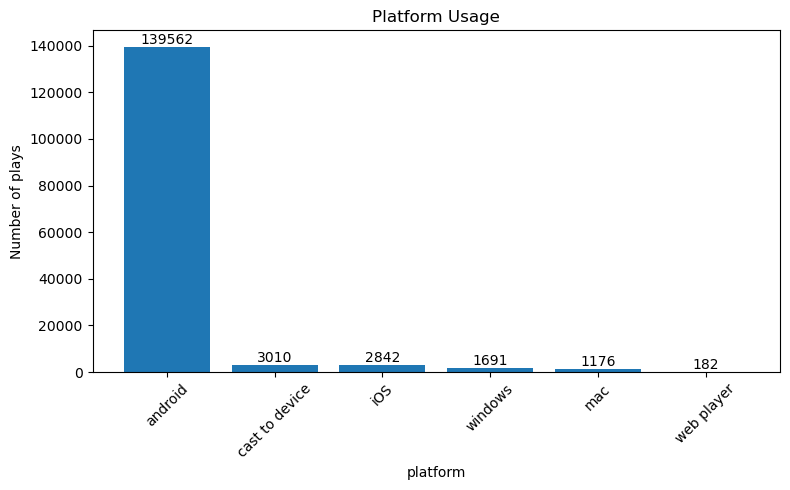

In [23]:
def bar_plot(df, column, title=None):
    counts = df[column].value_counts()
    plt.figure(figsize=(8, 5))
    bars = plt.bar(counts.index, counts.values)
    plt.bar_label(bars)                       # count on top of each bar
    plt.title(title or f'{column} distribution')
    plt.xlabel(column)
    plt.ylabel('Number of plays')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

bar_plot(df, 'platform', 'Platform Usage')

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Uniform_Resource_Identifier  148463 non-null  str           
 1   Time_Stamp                   148463 non-null  datetime64[us]
 2   platform                     148463 non-null  str           
 3   ms_played                    148463 non-null  int64         
 4   track_name                   148463 non-null  str           
 5   artist_name                  148463 non-null  str           
 6   album_name                   148463 non-null  str           
 7   reason_start                 148463 non-null  str           
 8   reason_end                   148463 non-null  str           
 9   shuffle                      148463 non-null  bool          
 10  skipped                      148463 non-null  bool          
dtypes: bool(2), datetime64[us](1), int64(

### Ms_played

In [25]:
df = df.rename(columns={'ms_played': 'Actually_Played(ms)'})

In [26]:
df

,Uniform_Resource_Identifier,Time_Stamp,platform,Actually_Played(ms),track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped
0,2J3n32GeLmMjwuAzyhcSNe,2013-07-08 02:44:34,web player,3185,"Say It, Just Say It",The Mowgli's,Waiting For The Dawn,autoplay,clickrow,False,False
1,1oHxIPqJyvAYHy0PVrDU98,2013-07-08 02:45:37,web player,61865,Drinking from the Bottle (feat. Tinie Tempah),Calvin Harris,18 Months,clickrow,clickrow,False,False
2,487OPlneJNni3NWC8SYqhW,2013-07-08 02:50:24,web player,285386,Born To Die,Lana Del Rey,Born To Die - The Paradise Edition,clickrow,unknown,False,False
3,5IyblF777jLZj1vGHG2UD3,2013-07-08 02:52:40,web player,134022,Off To The Races,Lana Del Rey,Born To Die - The Paradise Edition,trackdone,clickrow,False,False
4,0GgAAB0ZMllFhbNc3mAodO,2013-07-08 03:17:52,web player,0,Half Mast,Empire Of The Sun,Walking On A Dream,clickrow,nextbtn,False,False
...,...,...,...,...,...,...,...,...,...,...,...
148458,4Fz1WWr5o0OrlIcZxcyZtK,2024-12-15 23:06:19,android,1247,On The Way Home,John Mayer,Paradise Valley,fwdbtn,fwdbtn,True,True
148459,0qHMhBZqYb99yhX9BHcIkV,2024-12-15 23:06:21,android,1515,Magical Mystery Tour - Remastered 2009,The Beatles,Magical Mystery Tour,fwdbtn,fwdbtn,True,True
148460,0HHdujGjOZChTrl8lJWEIq,2024-12-15 23:06:22,android,1283,"Stop This Train - Live at the Nokia Theatre, L...",John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,True
148461,7peh6LUcdNPcMdrSH4JPsM,2024-12-15 23:06:23,android,1306,I Don't Trust Myself (With Loving You),John Mayer,Continuum,fwdbtn,fwdbtn,True,True


In [27]:
df['Actually_Played(ms)'].min(),df['Actually_Played(ms)'].max() 

(0, 1561125)

In [28]:
df.loc[df['Actually_Played(ms)'].idxmax()]

Uniform_Resource_Identifier    7ERSQrRptZVM7q3VOdM7OL
Time_Stamp                        2021-03-04 00:27:48
platform                                      android
Actually_Played(ms)                           1561125
track_name                      Tubular Bells - Pt. I
artist_name                             Mike Oldfield
album_name                              Tubular Bells
reason_start                                  appload
reason_end                                  trackdone
shuffle                                         False
skipped                                         False
Name: 93259, dtype: object

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Uniform_Resource_Identifier  148463 non-null  str           
 1   Time_Stamp                   148463 non-null  datetime64[us]
 2   platform                     148463 non-null  str           
 3   Actually_Played(ms)          148463 non-null  int64         
 4   track_name                   148463 non-null  str           
 5   artist_name                  148463 non-null  str           
 6   album_name                   148463 non-null  str           
 7   reason_start                 148463 non-null  str           
 8   reason_end                   148463 non-null  str           
 9   shuffle                      148463 non-null  bool          
 10  skipped                      148463 non-null  bool          
dtypes: bool(2), datetime64[us](1), int64(

In [30]:
df.duplicated(subset=['Uniform_Resource_Identifier', 'Time_Stamp']).sum()

np.int64(324)

In [31]:
key = ['Uniform_Resource_Identifier', 'Time_Stamp']
df[df.duplicated(subset=key, keep=False)].sort_values(key).head(10)

,Uniform_Resource_Identifier,Time_Stamp,platform,Actually_Played(ms),track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped
117709,02bJ6uGeHKfNOhIc9qyA8e,2022-05-23 07:29:17,android,3107,Wild Child,The Black Keys,Dropout Boogie,clickrow,fwdbtn,False,False
117723,02bJ6uGeHKfNOhIc9qyA8e,2022-05-23 07:29:17,android,102346,Wild Child,The Black Keys,Dropout Boogie,trackdone,endplay,False,False
117732,02bJ6uGeHKfNOhIc9qyA8e,2022-05-23 07:29:17,android,164866,Wild Child,The Black Keys,Dropout Boogie,clickrow,trackdone,False,False
12781,04Jdmzb6gfuSZxGfAFc2NH,2017-03-13 10:29:38,android,52592,It Comes Back To You,Imagine Dragons,Smoke + Mirrors,backbtn,logout,True,False
12782,04Jdmzb6gfuSZxGfAFc2NH,2017-03-13 10:29:38,android,0,It Comes Back To You,Imagine Dragons,Smoke + Mirrors,appload,fwdbtn,True,False
74461,09x9v1o51dbqi5H0u7UGfp,2020-08-12 22:37:32,android,11570,I Will - Remastered 2009,The Beatles,The Beatles,backbtn,fwdbtn,True,False
74473,09x9v1o51dbqi5H0u7UGfp,2020-08-12 22:37:32,android,1620,I Will - Remastered 2009,The Beatles,The Beatles,fwdbtn,fwdbtn,True,False
71899,0ESdtt9cjGZUkUbaubSrv2,2020-05-31 23:01:04,android,167239,Goodbye Blue Sky,Pink Floyd,The Wall,trackdone,trackdone,True,False
71902,0ESdtt9cjGZUkUbaubSrv2,2020-05-31 23:01:04,android,470,Goodbye Blue Sky,Pink Floyd,The Wall,fwdbtn,backbtn,True,False
116467,0EUSbTvyZfo9QOcxunL9Ro,2022-04-29 22:47:35,android,2256,In Your Atmosphere - Live at the Nokia Theatre...,John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,False


In [32]:
df['was_played'] = df['Actually_Played(ms)'] > 0

In [33]:
df

,Uniform_Resource_Identifier,Time_Stamp,platform,Actually_Played(ms),track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped,was_played
0,2J3n32GeLmMjwuAzyhcSNe,2013-07-08 02:44:34,web player,3185,"Say It, Just Say It",The Mowgli's,Waiting For The Dawn,autoplay,clickrow,False,False,True
1,1oHxIPqJyvAYHy0PVrDU98,2013-07-08 02:45:37,web player,61865,Drinking from the Bottle (feat. Tinie Tempah),Calvin Harris,18 Months,clickrow,clickrow,False,False,True
2,487OPlneJNni3NWC8SYqhW,2013-07-08 02:50:24,web player,285386,Born To Die,Lana Del Rey,Born To Die - The Paradise Edition,clickrow,unknown,False,False,True
3,5IyblF777jLZj1vGHG2UD3,2013-07-08 02:52:40,web player,134022,Off To The Races,Lana Del Rey,Born To Die - The Paradise Edition,trackdone,clickrow,False,False,True
4,0GgAAB0ZMllFhbNc3mAodO,2013-07-08 03:17:52,web player,0,Half Mast,Empire Of The Sun,Walking On A Dream,clickrow,nextbtn,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
148458,4Fz1WWr5o0OrlIcZxcyZtK,2024-12-15 23:06:19,android,1247,On The Way Home,John Mayer,Paradise Valley,fwdbtn,fwdbtn,True,True,True
148459,0qHMhBZqYb99yhX9BHcIkV,2024-12-15 23:06:21,android,1515,Magical Mystery Tour - Remastered 2009,The Beatles,Magical Mystery Tour,fwdbtn,fwdbtn,True,True,True
148460,0HHdujGjOZChTrl8lJWEIq,2024-12-15 23:06:22,android,1283,"Stop This Train - Live at the Nokia Theatre, L...",John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,True,True
148461,7peh6LUcdNPcMdrSH4JPsM,2024-12-15 23:06:23,android,1306,I Don't Trust Myself (With Loving You),John Mayer,Continuum,fwdbtn,fwdbtn,True,True,True


In [34]:
df[df['Actually_Played(ms)'] > 900000].shape

(20, 12)

### Track Name, Artist Name, Album Name

In [35]:
# To avoid Case Sensitivity we going to use string strip method 
def striping(df, cols):
    for col in cols:
        df[col] = df[col].str.strip()
    return df

df = striping(df, ['track_name', 'artist_name', 'album_name'])

In [36]:
df

,Uniform_Resource_Identifier,Time_Stamp,platform,Actually_Played(ms),track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped,was_played
0,2J3n32GeLmMjwuAzyhcSNe,2013-07-08 02:44:34,web player,3185,"Say It, Just Say It",The Mowgli's,Waiting For The Dawn,autoplay,clickrow,False,False,True
1,1oHxIPqJyvAYHy0PVrDU98,2013-07-08 02:45:37,web player,61865,Drinking from the Bottle (feat. Tinie Tempah),Calvin Harris,18 Months,clickrow,clickrow,False,False,True
2,487OPlneJNni3NWC8SYqhW,2013-07-08 02:50:24,web player,285386,Born To Die,Lana Del Rey,Born To Die - The Paradise Edition,clickrow,unknown,False,False,True
3,5IyblF777jLZj1vGHG2UD3,2013-07-08 02:52:40,web player,134022,Off To The Races,Lana Del Rey,Born To Die - The Paradise Edition,trackdone,clickrow,False,False,True
4,0GgAAB0ZMllFhbNc3mAodO,2013-07-08 03:17:52,web player,0,Half Mast,Empire Of The Sun,Walking On A Dream,clickrow,nextbtn,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
148458,4Fz1WWr5o0OrlIcZxcyZtK,2024-12-15 23:06:19,android,1247,On The Way Home,John Mayer,Paradise Valley,fwdbtn,fwdbtn,True,True,True
148459,0qHMhBZqYb99yhX9BHcIkV,2024-12-15 23:06:21,android,1515,Magical Mystery Tour - Remastered 2009,The Beatles,Magical Mystery Tour,fwdbtn,fwdbtn,True,True,True
148460,0HHdujGjOZChTrl8lJWEIq,2024-12-15 23:06:22,android,1283,"Stop This Train - Live at the Nokia Theatre, L...",John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,True,True
148461,7peh6LUcdNPcMdrSH4JPsM,2024-12-15 23:06:23,android,1306,I Don't Trust Myself (With Loving You),John Mayer,Continuum,fwdbtn,fwdbtn,True,True,True


### Reason End, Reason start

In [37]:
df['reason_start'].value_counts()

reason_start
trackdone     75834
fwdbtn        53678
clickrow      10978
appload        3729
backbtn        2198
playbtn        1441
remote          433
trackerror      120
unknown          23
nextbtn          21
popup             5
endplay           2
autoplay          1
Name: count, dtype: int64

In [38]:
df['reason_end'].value_counts()

reason_end
trackdone                       76296
fwdbtn                          53351
endplay                          9869
logout                           4364
backbtn                          2173
unexpected-exit-while-paused     1724
unknown                           268
remote                            224
unexpected-exit                   118
clickrow                           34
nextbtn                            21
appload                             7
popup                               6
reload                              4
trackerror                          4
Name: count, dtype: int64

In [39]:
pd.crosstab(df['skipped'], df['reason_end'])

reason_end,appload,backbtn,clickrow,endplay,fwdbtn,logout,nextbtn,popup,reload,remote,trackdone,trackerror,unexpected-exit,unexpected-exit-while-paused,unknown
skipped,,,,,,,,,,,,,,,
False,0,1932,30,7863,47908,4364,21,0,4,224,76274,4,118,1724,252
True,7,241,4,2006,5443,0,0,6,0,0,22,0,0,0,16


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Uniform_Resource_Identifier  148463 non-null  str           
 1   Time_Stamp                   148463 non-null  datetime64[us]
 2   platform                     148463 non-null  str           
 3   Actually_Played(ms)          148463 non-null  int64         
 4   track_name                   148463 non-null  str           
 5   artist_name                  148463 non-null  str           
 6   album_name                   148463 non-null  str           
 7   reason_start                 148463 non-null  str           
 8   reason_end                   148463 non-null  str           
 9   shuffle                      148463 non-null  bool          
 10  skipped                      148463 non-null  bool          
 11  was_played                   148463 n

In [41]:
df['Actually_Played(ms)'].describe()

count    1.484630e+05
mean     1.280384e+05
std      1.178061e+05
min      0.000000e+00
25%      2.780000e+03
50%      1.383860e+05
75%      2.183070e+05
max      1.561125e+06
Name: Actually_Played(ms), dtype: float64

# Clean Data 

In [49]:
data = df
data

,Uniform_Resource_Identifier,Time_Stamp,platform,Actually_Played(ms),track_name,artist_name,album_name,reason_start,reason_end,shuffle,skipped,was_played,minutes_played
0,2J3n32GeLmMjwuAzyhcSNe,2013-07-08 02:44:34,web player,3185,"Say It, Just Say It",The Mowgli's,Waiting For The Dawn,autoplay,clickrow,False,False,True,0.053083
1,1oHxIPqJyvAYHy0PVrDU98,2013-07-08 02:45:37,web player,61865,Drinking from the Bottle (feat. Tinie Tempah),Calvin Harris,18 Months,clickrow,clickrow,False,False,True,1.031083
2,487OPlneJNni3NWC8SYqhW,2013-07-08 02:50:24,web player,285386,Born To Die,Lana Del Rey,Born To Die - The Paradise Edition,clickrow,unknown,False,False,True,4.756433
3,5IyblF777jLZj1vGHG2UD3,2013-07-08 02:52:40,web player,134022,Off To The Races,Lana Del Rey,Born To Die - The Paradise Edition,trackdone,clickrow,False,False,True,2.233700
4,0GgAAB0ZMllFhbNc3mAodO,2013-07-08 03:17:52,web player,0,Half Mast,Empire Of The Sun,Walking On A Dream,clickrow,nextbtn,False,False,False,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
148458,4Fz1WWr5o0OrlIcZxcyZtK,2024-12-15 23:06:19,android,1247,On The Way Home,John Mayer,Paradise Valley,fwdbtn,fwdbtn,True,True,True,0.020783
148459,0qHMhBZqYb99yhX9BHcIkV,2024-12-15 23:06:21,android,1515,Magical Mystery Tour - Remastered 2009,The Beatles,Magical Mystery Tour,fwdbtn,fwdbtn,True,True,True,0.025250
148460,0HHdujGjOZChTrl8lJWEIq,2024-12-15 23:06:22,android,1283,"Stop This Train - Live at the Nokia Theatre, L...",John Mayer,Where the Light Is: John Mayer Live In Los Ang...,fwdbtn,fwdbtn,True,True,True,0.021383
148461,7peh6LUcdNPcMdrSH4JPsM,2024-12-15 23:06:23,android,1306,I Don't Trust Myself (With Loving You),John Mayer,Continuum,fwdbtn,fwdbtn,True,True,True,0.021767


In [43]:
data.shape

(148463, 12)

In [44]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 148463 entries, 0 to 148462
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Uniform_Resource_Identifier  148463 non-null  str           
 1   Time_Stamp                   148463 non-null  datetime64[us]
 2   platform                     148463 non-null  str           
 3   Actually_Played(ms)          148463 non-null  int64         
 4   track_name                   148463 non-null  str           
 5   artist_name                  148463 non-null  str           
 6   album_name                   148463 non-null  str           
 7   reason_start                 148463 non-null  str           
 8   reason_end                   148463 non-null  str           
 9   shuffle                      148463 non-null  bool          
 10  skipped                      148463 non-null  bool          
 11  was_played                   148463 n

In [45]:
data['Actually_Played(ms)'].describe()

count    1.484630e+05
mean     1.280384e+05
std      1.178061e+05
min      0.000000e+00
25%      2.780000e+03
50%      1.383860e+05
75%      2.183070e+05
max      1.561125e+06
Name: Actually_Played(ms), dtype: float64

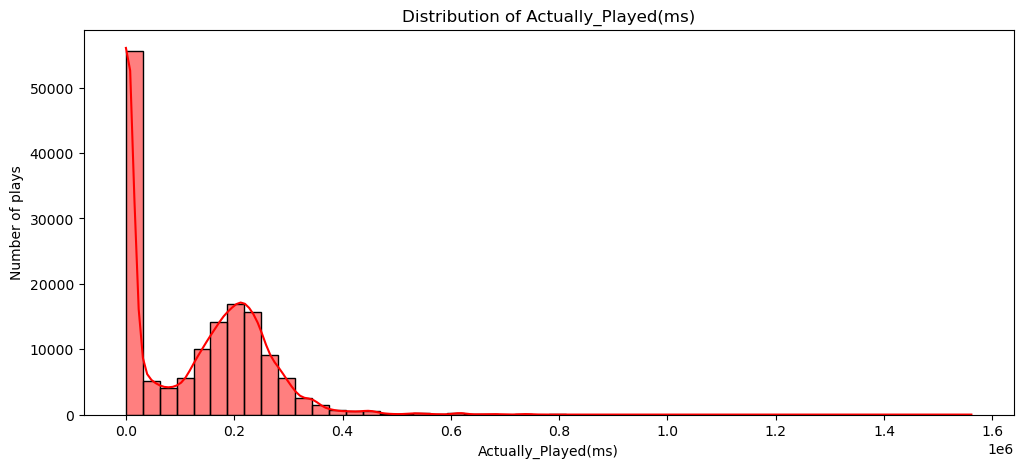

In [46]:
def dist_plot(df, column, bins=50, title=None):
    plt.figure(figsize=(12, 5))
    sns.histplot(df[column], bins=bins, kde = True, color='red')
    plt.title(title or f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Number of plays')
    plt.show()

dist_plot(df, 'Actually_Played(ms)')

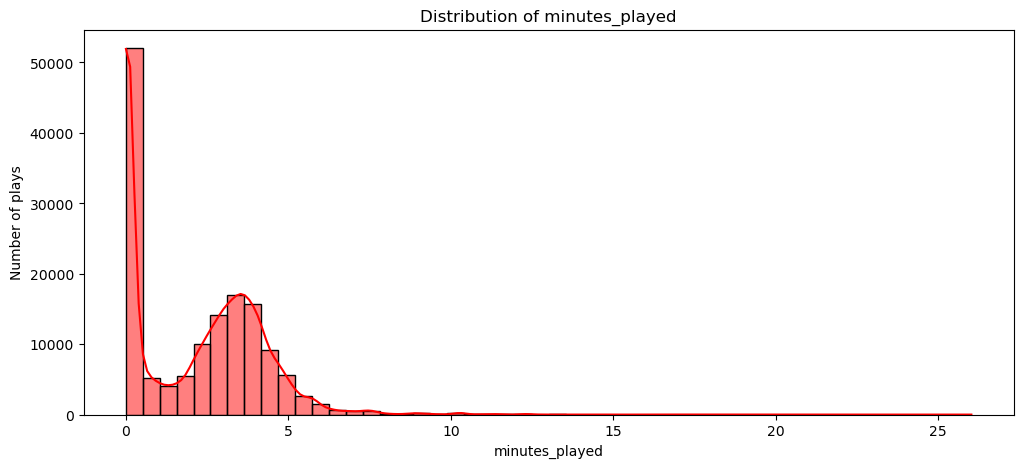

In [47]:
df['minutes_played'] = df['Actually_Played(ms)'] / 60000
dist_plot(df[df['minutes_played'] > 0], 'minutes_played')

In [48]:
import os

file_name = 'Cleaned_data_spotify_history.csv'

if os.path.exists(file_name):
    print('File already exists, not saved again.')
else:
    df.to_csv(file_name, index=False)
    print('File saved.')

File already exists, not saved again.
